# Homework 7 — Regression

## tl;dr

| Question | Result | Closest answer |
|---|---|---|
| Q1: X correlated with the full-model error? | Population correlation = 0 | **A — 0** |
| Q2: X correlated with the error after omitting W? | Population correlation = 0.50 | **B — 0.50** |
| Q3: X coefficient as W increases? | 0.858, 1.383, 1.958 at W near −1, 0, 1 | **B — increasing** |
| Q4: Empirical SD / mean reported SE as autocorrelation rises? | Ratio increases | **C — ratio increases** |

All four quiz questions and answer choices are included below. Homework Reflection 7 follows the quiz analysis with two written paragraphs and executable simulations.

## Context & Methods

**Inputs:** supplied Week 7 coding quiz, `Homework Instructions + Data Files/homework_7.1.csv`, and `Homework Refelction Instructions/Homework-Reflections-5-8`. X is the focal predictor, Y the outcome, and W and Z are the other variables in the respective questions. Include an intercept in every fitted regression.

### Key Assumptions

- Q1–Q2: all separately generated normal error terms are independent. “Error” means the structural equation error, rather than the fitted OLS residual, which is orthogonal to included regressors by construction.
- Q3: use a prespecified ±0.1 band around each W target; repeat with ±0.05 and ±0.2 to check the direction. Local regressions include X and Z; these bands approximate holding W fixed.
- Q4: the prompt permits a chosen model. Use $X_t=u_t$ and $Y_t=2X_t+v_t$, where u and v are separate independent paths from the supplied `make_error` function. Fit 1,000 independent trials of 1,000 observations at each correlation constant. Report the ordinary OLS standard error, whose independent-error assumption is being examined.
- Reflection 7 uses separate, seeded simulations with known population coefficients. These simulations are illustrations, not observations from the CSV.

Dependencies: Python 3, NumPy, pandas, SciPy, matplotlib, scikit-learn, and IPython. Run top-to-bottom from the project root or a subfolder.

## Data

### 1. Setup and OLS calculation

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from IPython.display import display

pd.set_option('display.precision', 6)
plt.rcParams.update({
    'figure.figsize': (9, 4.8), 'figure.dpi': 110, 'font.size': 11,
    'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#E5E7EB', 'axes.axisbelow': True,
    'text.color': '#1F2937', 'axes.labelcolor': '#1F2937',
})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'

def fit_ols(y, predictors):
    # Add an intercept and calculate conventional, homoskedastic OLS SEs.
    y = np.asarray(y, dtype=float)
    predictors = np.asarray(predictors, dtype=float)
    if predictors.ndim == 1:
        predictors = predictors[:, None]
    design = np.column_stack([np.ones(len(y)), predictors])
    assert np.linalg.matrix_rank(design) == design.shape[1]
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - design @ beta
    df = len(y) - design.shape[1]
    variance = residuals @ residuals / df
    se = np.sqrt(np.diag(np.linalg.inv(design.T @ design)) * variance)
    pvalues = 2 * stats.t.sf(np.abs(beta / se), df)
    return beta, se, pvalues

def locate_source(filename):
    for folder in (Path.cwd(), *Path.cwd().parents):
        for candidate in [folder / 'Homework Instructions + Data Files' / filename,
                          folder / filename]:
            if candidate.is_file():
                return candidate.resolve()
    raise FileNotFoundError(filename)

SOURCE_PATH = locate_source('homework_7.1.csv')
print('Source:', SOURCE_PATH.relative_to(SOURCE_PATH.parent.parent))
print('SHA-256:', hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest())

Source: Homework Instructions + Data Files/homework_7.1.csv
SHA-256: 67b0854db6a112406e10c65b7151890430dd575dfb81d0e52a88eccdb522079b


### 2. Load and validate the supplied data

In [2]:
data = pd.read_csv(SOURCE_PATH)
required = ['X', 'W', 'Z', 'Y']
assert set(required).issubset(data.columns)
assert all(pd.api.types.is_numeric_dtype(data[c]) for c in required)
assert np.isfinite(data[required].to_numpy()).all()
display(pd.DataFrame({
    'Check': ['Rows', 'Missing values', 'Duplicate rows'],
    'Result': [len(data), int(data[required].isna().sum().sum()),
               int(data[required].duplicated().sum())],
}))
display(data.head())

,Check,Result
0,Rows,10000
1,Missing values,0
2,Duplicate rows,0


,X,W,Z,Y
0,1.137055,1.221768,0.327829,1.944532
1,-0.112905,0.465835,0.599650,0.655514
2,2.077755,1.795414,-0.063393,5.934411
3,0.456373,-0.512159,1.177413,-0.188064
4,-1.012402,0.080002,-0.275697,-0.533775


## Results

### Question 1 — correlation with the full-model error

**Prompt:** Suppose the process is modeled as:

```python
W = np.random.normal(0, 1, (1000,))
X = W + np.random.normal(0, 1, (1000,))
Z = np.random.normal(0, 1, (1000,))
Y = X + Z + W + np.random.normal(0, 1, (1000,))
```

Which is closest to the correlation of X with the error term in the equation for Y?

**Choices:** A: 0 · B: 1.0 · C: −0.50 · D: 0.75 · E: 0.5

**Answer: A — 0.** In the full equation, the error is the last independent normal draw, $\varepsilon_Y$. Since $X=W+\varepsilon_X$ and neither component is correlated with $\varepsilon_Y$, the population correlation is zero. A sample correlation may differ slightly from zero.

### Question 2 — correlation after omitting W

**Prompt:** If Y is written as depending on X and Z only, W is part of the error term. Which is closest to the expected correlation of X with that error?

**Choices:** A: 0 · B: 0.50 · C: 0.75 · D: 1.0 · E: −0.50

**Answer: B — 0.50.** The structural error becomes $e=W+\varepsilon_Y$. Independent unit-variance draws give $Cov(X,e)=Var(W)=1$, $Var(X)=2$, and $Var(e)=2$, so $Corr(X,e)=1/\sqrt{2\times2}=0.5$. The omitted W therefore violates the exogeneity condition for X.

In [3]:
# A reproducible 1,000-observation illustration of the supplied process.
rng = np.random.default_rng(7021)
W = rng.normal(size=1000)
X = W + rng.normal(size=1000)
Z = rng.normal(size=1000)
outcome_noise = rng.normal(size=1000)
Y = X + Z + W + outcome_noise
correlation_results = pd.DataFrame({
    'Equation': ['Full model: X, Z, W', 'W omitted: X, Z'],
    'Population correlation': [0.0, 0.5],
    'Sample correlation': [np.corrcoef(X, outcome_noise)[0, 1],
                           np.corrcoef(X, W + outcome_noise)[0, 1]],
})
display(correlation_results)
# Simulation is illustrative; the exact answers come from population covariance.
assert 1 / np.sqrt(2 * 2) == 0.5

,Equation,Population correlation,Sample correlation
0,"Full model: X, Z, W",0.0,0.029254
1,"W omitted: X, Z",0.5,0.496141


### Question 3 — control for W with local bands

**Prompt:** In `homework_7.1.csv`, control for W by regressing Y on X and Z at the following constant values of W: −1, 0, and 1. You cannot literally use a constant W because that leaves too few data points. Is the X coefficient:

**Choices:** A: staying about the same (within about 0.2) as W increases · B: increasing · C: decreasing

**Answer: B — increasing.** Use observations within ±0.1 of each W target, then regress Y on X and Z with an intercept. The X coefficients are **0.857978**, **1.383211**, and **1.958097**. Narrow bands approximate conditioning on W; the remaining within-band W variation means this is not exact conditioning. The direction persists at narrower and wider bands.

,Half-width,W target,Rows,Mean W,Intercept,X coefficient,Z coefficient
3,0.1,-1,488,-0.994595,-1.217519,0.857978,-0.587480
4,0.1,0,780,-0.002603,0.001863,1.383211,-0.565127
5,0.1,1,455,0.991247,1.088319,1.958097,-0.568191


Half-width,0.05,0.10,0.20
W target,,,
-1,0.839350,0.857978,0.869937
0,1.353052,1.383211,1.417743
1,2.047258,1.958097,1.934333


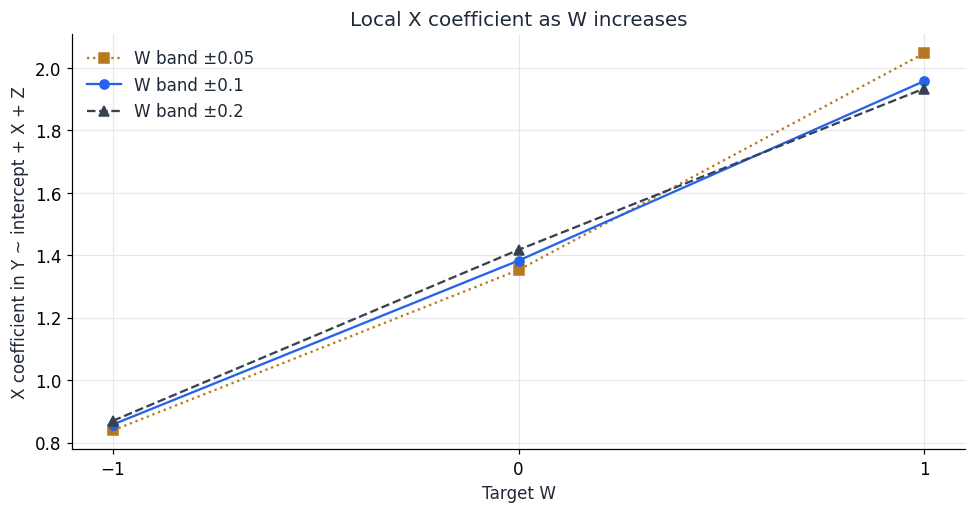

In [4]:
local_rows = []
for half_width in [0.05, 0.1, 0.2]:
    for target in [-1, 0, 1]:
        subset = data.loc[data['W'].between(target - half_width, target + half_width)]
        beta, se, pvalues = fit_ols(subset['Y'], subset[['X', 'Z']])
        reference = LinearRegression().fit(subset[['X', 'Z']], subset['Y'])
        np.testing.assert_allclose(beta, np.r_[reference.intercept_, reference.coef_])
        local_rows.append({'Half-width': half_width, 'W target': target, 'Rows': len(subset),
                           'Mean W': subset['W'].mean(), 'Intercept': beta[0],
                           'X coefficient': beta[1], 'Z coefficient': beta[2]})
local_results = pd.DataFrame(local_rows)
display(local_results.loc[local_results['Half-width'] == 0.1])
display(local_results.pivot(index='W target', columns='Half-width', values='X coefficient'))
assert all(np.all(np.diff(group['X coefficient']) > 0)
           for _, group in local_results.groupby('Half-width'))

fig, ax = plt.subplots()
for width, marker, style, color in [(0.05, 's', ':', GOLD), (0.1, 'o', '-', BLUE),
                                   (0.2, '^', '--', DARK)]:
    group = local_results.loc[local_results['Half-width'] == width]
    ax.plot(group['W target'], group['X coefficient'], marker=marker, linestyle=style,
            color=color, label=f'W band ±{width}')
ax.set(title='Local X coefficient as W increases', xlabel='Target W',
       ylabel='X coefficient in Y ~ intercept + X + Z', xticks=[-1, 0, 1])
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Question 4 — autocorrelation and standard-error accuracy

**Prompt:** Use the following function as the error for both the treatment X and the outcome Y (other covariates may use ordinary normal noise). As `corr_const` rises from 0.2 to 0.5 to 0.8, calculate (i) the standard deviation of the estimated X coefficient across many trials and (ii) the mean reported standard error of that coefficient. Include an intercept.

```python
def make_error(corr_const, num):
    err = list()
    prev = np.random.normal(0, 1)
    for n in range(num):
        prev = corr_const * prev + (1 - corr_const) * np.random.normal(0, 1)
        err.append(prev)
    return np.array(err)
```

**Choices:** A: (i) and (ii) remain about the same · B: ratio (i)/(ii) decreases · C: ratio (i)/(ii) increases · D: (i) and (ii) differ, but their ratio stays about the same

**Answer: C — the ratio increases.** Use separate error paths for X and Y in each trial so their innovations are independent. The ordinary OLS standard error treats errors as independent across observations and increasingly understates coefficient variation when both series become more persistent. The simulation below preserves the supplied function, including its initialization and innovation scaling.

In [5]:
def make_error(corr_const, num):
    err = list()
    prev = np.random.normal(0, 1)
    for n in range(num):
        prev = corr_const * prev + (1 - corr_const) * np.random.normal(0, 1)
        err.append(prev)
    return np.array(err)

np.random.seed(7024)
N_OBSERVATIONS = 1000
N_TRIALS = 1000
TRUE_X_COEFFICIENT = 2.0
autocorrelation_rows = []
first_trial = None
for corr_const in [0.2, 0.5, 0.8]:
    for trial in range(N_TRIALS):
        x = make_error(corr_const, N_OBSERVATIONS)
        outcome_error = make_error(corr_const, N_OBSERVATIONS)
        y = TRUE_X_COEFFICIENT * x + outcome_error
        beta, se, pvalues = fit_ols(y, x)
        if first_trial is None:
            first_trial = (x.copy(), y.copy(), beta.copy(), se.copy())
        autocorrelation_rows.append({'corr_const': corr_const, 'trial': trial + 1,
                                     'X coefficient': beta[1], 'Reported SE': se[1]})
autocorrelation_trials = pd.DataFrame(autocorrelation_rows)
autocorrelation_summary = autocorrelation_trials.groupby('corr_const').agg(
    trials=('trial', 'size'), mean_coefficient=('X coefficient', 'mean'),
    empirical_SD=('X coefficient', 'std'), mean_reported_SE=('Reported SE', 'mean'),
).reset_index()
autocorrelation_summary['SD / mean SE'] = (
    autocorrelation_summary['empirical_SD'] / autocorrelation_summary['mean_reported_SE'])
display(autocorrelation_summary)
assert np.all(np.diff(autocorrelation_summary['SD / mean SE']) > 0)

# Independent verification of conventional slope SE on one trial.
check_x, check_y, check_beta, check_se = first_trial
reference = stats.linregress(check_x, check_y)
np.testing.assert_allclose(check_beta, [reference.intercept, reference.slope])
np.testing.assert_allclose(check_se[1], reference.stderr)
print('Verified one trial against scipy.stats.linregress.')

,corr_const,trials,mean_coefficient,empirical_SD,mean_reported_SE,SD / mean SE
0,0.2,1000,2.000529,0.033892,0.031711,1.068784
1,0.5,1000,1.998281,0.039917,0.031584,1.263850
2,0.8,1000,2.001990,0.067619,0.031647,2.136690


Verified one trial against scipy.stats.linregress.


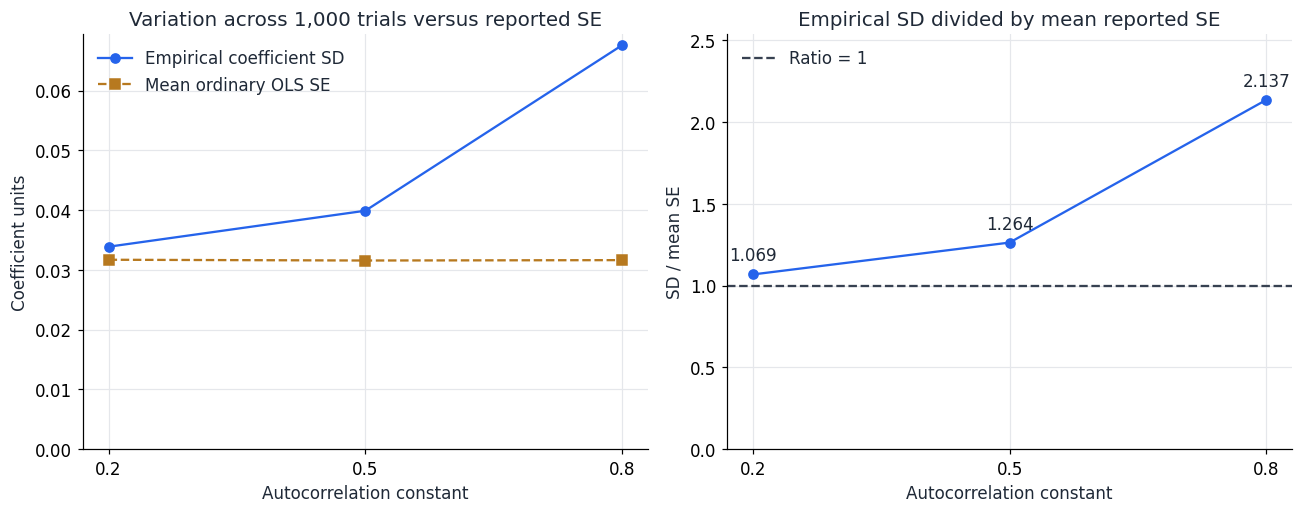

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
s = autocorrelation_summary
axes[0].plot(s['corr_const'], s['empirical_SD'], marker='o', color=BLUE, label='Empirical coefficient SD')
axes[0].plot(s['corr_const'], s['mean_reported_SE'], marker='s', linestyle='--',
             color=GOLD, label='Mean ordinary OLS SE')
axes[0].set(title='Variation across 1,000 trials versus reported SE',
            xlabel='Autocorrelation constant', ylabel='Coefficient units', ylim=(0, None))
axes[0].legend(frameon=False)
axes[1].plot(s['corr_const'], s['SD / mean SE'], marker='o', color=BLUE)
axes[1].axhline(1, color=DARK, linestyle='--', label='Ratio = 1')
for c, ratio in zip(s['corr_const'], s['SD / mean SE']):
    axes[1].annotate(f'{ratio:.3f}', (c, ratio), xytext=(0, 9), textcoords='offset points', ha='center')
axes[1].set(title='Empirical SD divided by mean reported SE',
            xlabel='Autocorrelation constant', ylabel='SD / mean SE', ylim=(0, s['SD / mean SE'].max() + 0.4))
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks([0.2, 0.5, 0.8])
fig.tight_layout()
plt.show()

The innovation multiplier (1 − corr_const) also changes the variance of each error series, so the numerical comparison follows this exact generator. Since X and the outcome error use the same multiplier, their scale changes roughly cancel in slope uncertainty; increasing serial dependence still raises the empirical-SD-to-SE ratio. A single error path reused for both variables would create endogeneity and answer a different question.

### 5. Collect the quiz answers

In [7]:
quiz_answers = pd.DataFrame({
    'Question': ['Q1', 'Q2', 'Q3', 'Q4'],
    'Answer': ['A — 0', 'B — 0.50', 'B — increasing', 'C — ratio increases'],
})
display(quiz_answers)

,Question,Answer
0,Q1,A — 0
1,Q2,B — 0.50
2,Q3,B — increasing
3,Q4,C — ratio increases


## Homework Reflection 7

### 1. Create a regression with an omitted confounder; determine the direction of bias and explain it.

I generate independent standard-normal Z, treatment noise, and outcome noise, then set X = Z + treatment noise and Y = 2X + 3Z + outcome noise. Z is a confounder because it increases both X and Y. The true causal X coefficient is 2, but leaving Z out overestimates it: the fitted X-only slope is **3.463721**, compared with **1.974390** when Z is included. In the population, the omitted-variable bias is 3 × Cov(X,Z)/Var(X) = 3/2, so the X-only slope is 3.5. The omitted model attributes some of Z’s positive contribution to X. This is bias in the regression coefficient as an estimate of the causal effect; an observed correlation is not itself the causal coefficient.

### 2. Run a regression with a zero coefficient 1,000 times; report the smallest p-value and explain repeated analysis.

For each of 1,000 independent datasets of 100 observations, I generate independent standard-normal W, X, and outcome noise, set Y = 2X + outcome noise, and regress Y on an intercept, X, and W. W’s true coefficient is exactly zero. With seed 7027, the smallest two-sided W p-value is **0.000153434** (trial **279**), and **46** trials produce p < 0.05. This does not mean W’s coefficient is truly nonzero: under the null, a p-value measures the probability of a test statistic at least as extreme as the observed one, not the probability that the null is true. Selecting the smallest result after repeated testing creates false-positive evidence; with independent tests the probability of at least one p < 0.05 is 1 − 0.95^1000, essentially one. Prespecify the test, report all attempts, and if treating the 1,000 tests as a family use a multiplicity correction: the Bonferroni threshold is 0.05/1000 = **0.00005**, which even this minimum does not meet.

,Model,X coefficient
0,True causal coefficient,2.000000
1,X only: confounder omitted,3.463721
2,X and Z: confounder included,1.974390


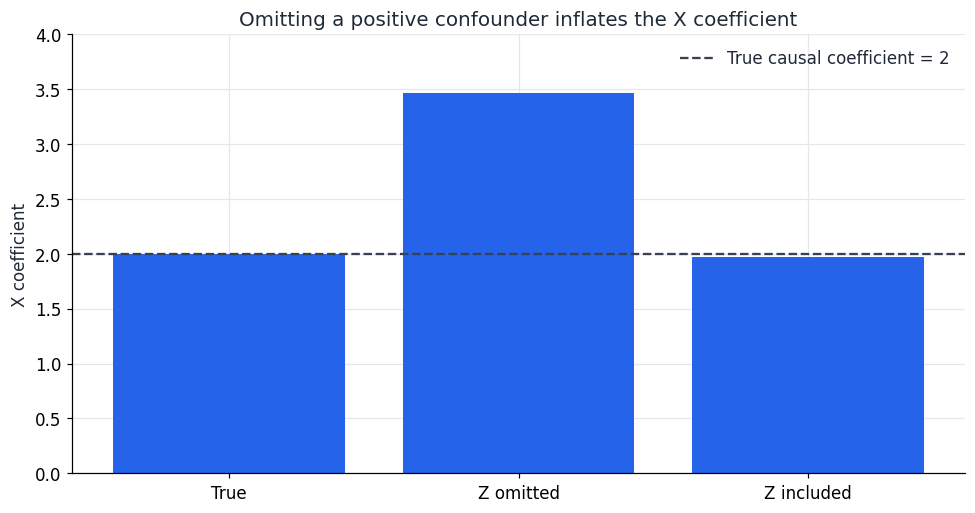

In [8]:
# Reflection 1: positive omitted-variable bias with a known true coefficient.
rng = np.random.default_rng(42)
n = 1000
confounder = rng.normal(size=n)
x = confounder + rng.normal(size=n)
y = 2 * x + 3 * confounder + rng.normal(size=n)
omitted_beta, _, _ = fit_ols(y, x)
adjusted_beta, _, _ = fit_ols(y, np.column_stack([x, confounder]))
reflection_bias = pd.DataFrame({
    'Model': ['True causal coefficient', 'X only: confounder omitted', 'X and Z: confounder included'],
    'X coefficient': [2.0, omitted_beta[1], adjusted_beta[1]],
})
display(reflection_bias)
np.testing.assert_allclose(adjusted_beta[1:], LinearRegression().fit(np.c_[x, confounder], y).coef_)

fig, ax = plt.subplots()
ax.bar(['True', 'Z omitted', 'Z included'], reflection_bias['X coefficient'], color=BLUE)
ax.axhline(2, color=DARK, linestyle='--', label='True causal coefficient = 2')
ax.set(title='Omitting a positive confounder inflates the X coefficient',
       ylabel='X coefficient', ylim=(0, 4))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

,Measure,Value
0,Smallest W p-value,0.000153
1,Trial with smallest p-value,279.000000
2,W coefficient in that trial,0.424594
3,Trials with p < 0.05,46.000000
4,Bonferroni threshold,0.000050


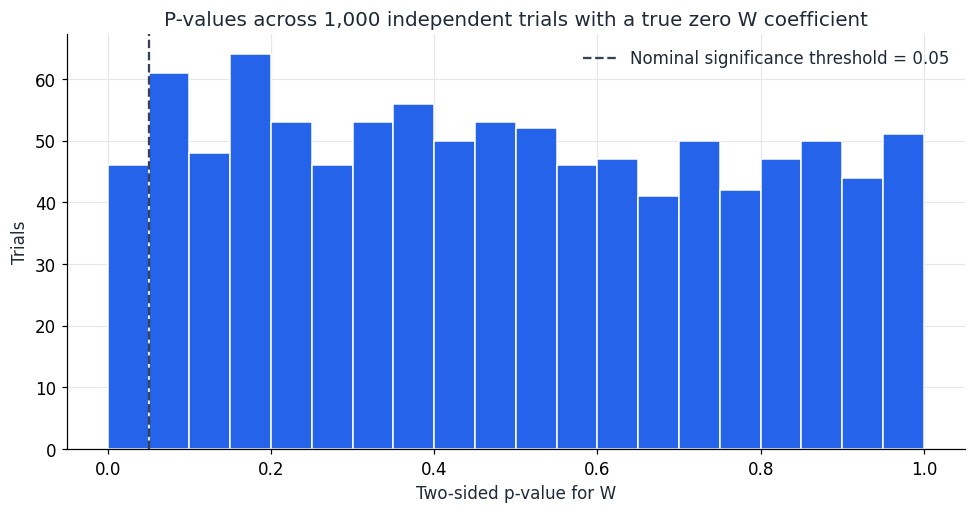

In [9]:
# Reflection 2: every trial has a true W coefficient of zero.
rng = np.random.default_rng(7027)
reflection_trials = []
for trial in range(1000):
    w = rng.normal(size=100)
    x = rng.normal(size=100)
    y = 2 * x + rng.normal(size=100)
    beta, se, pvalues = fit_ols(y, np.column_stack([x, w]))
    reflection_trials.append({'Trial': trial + 1, 'W coefficient': beta[2], 'W p-value': pvalues[2]})
reflection_trials = pd.DataFrame(reflection_trials)
best = reflection_trials.loc[reflection_trials['W p-value'].idxmin()]
false_positives = int((reflection_trials['W p-value'] < 0.05).sum())
bonferroni_threshold = 0.05 / len(reflection_trials)
display(pd.DataFrame({
    'Measure': ['Smallest W p-value', 'Trial with smallest p-value',
                'W coefficient in that trial', 'Trials with p < 0.05', 'Bonferroni threshold'],
    'Value': [best['W p-value'], best['Trial'], best['W coefficient'], false_positives, bonferroni_threshold],
}))
assert best['W p-value'] > bonferroni_threshold

fig, ax = plt.subplots()
ax.hist(reflection_trials['W p-value'], bins=np.linspace(0, 1, 21), color=BLUE, edgecolor='white')
ax.axvline(0.05, color=DARK, linestyle='--', label='Nominal significance threshold = 0.05')
ax.set(title='P-values across 1,000 independent trials with a true zero W coefficient',
       xlabel='Two-sided p-value for W', ylabel='Trials')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Takeaways

**Quiz selections: Q1 A, Q2 B, Q3 B, Q4 C.** Omitting a variable correlated with X can make the structural error correlated with X; local regressions reveal an increasing X coefficient with W in the supplied data. Autocorrelation reduces the accuracy of ordinary OLS standard errors, while selecting the smallest p-value from repeated tests can manufacture apparent evidence for a coefficient known to be zero.

### Reproducibility

The source checksum, random seeds, simulation sizes, and band widths are recorded above. All results are saved in the executed notebook.

In [10]:
print('Python:', platform.python_version())
for package in ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn', 'nbformat', 'nbclient']:
    print(f'{package}: {importlib.metadata.version(package)}')

Python: 3.13.5
numpy: 2.4.1
pandas: 3.0.0
scipy: 1.17.0
matplotlib: 3.10.8
scikit-learn: 1.8.0
nbformat: 5.10.4
nbclient: 0.10.4
